# Capítulo 5 · Actividad: Titanic, ¿árbol o vecinos?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/04_actividad_titanic_arbol_knn.ipynb)

Compara un **árbol de decisión** y **KNN** para predecir si un pasajero del Titanic sobrevivió. Primero entiende los datos; el preprocesamiento lo decides tú. Los dos modelos tienen que evaluarse sobre la misma división de train y test, y con las mismas particiones de validación cruzada.

Cada fila es un pasajero. Para esta actividad usa las siguientes variables:

| Variable | Significado |
|---|---|
| `survived` | **Target**: `0` = no sobrevivió, `1` = sobrevivió |
| `pclass` | Clase del boleto: primera, segunda o tercera |
| `sex` | Sexo del pasajero |
| `age` | Edad en años |
| `sibsp` | Número de hermanos y cónyuges a bordo |
| `parch` | Número de padres e hijos a bordo |
| `fare` | Tarifa pagada |
| `embarked` | Puerto de embarque: `C`, `Q` o `S` |

Hay valores faltantes en `age` y `embarked`. Las clases de supervivencia no están balanceadas y las variables numéricas tienen escalas distintas.

**Usa únicamente las siete variables predictoras de la tabla.** El CSV contiene otras columnas: `alive`, por ejemplo, expresa la misma respuesta que `survived`. Incluirla entre las entradas sería una fuga de información: el modelo recibiría la respuesta que debe predecir. Tampoco incluyas `survived` entre las entradas.

Como mínimo, tu notebook debe incluir:

- La exploración de antes de modelar: forma de la tabla, nulos, balance de supervivencia, distribuciones y relación de las variables con la supervivencia.
- Una división estratificada de train y test y validación cruzada estratificada sobre train. Usa `random_state=42` en la división, en el árbol y al mezclar las particiones de validación.
- Un **árbol de decisión** y un **KNN**, los dos para clasificar. Decide cómo tratar los nulos, cómo codificar las variables categóricas y si estandarizas las numéricas: a KNN la escala le importa, al árbol no. Integra el preprocesamiento en un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada partición.
- La profundidad del árbol (y `min_samples_leaf`, si quieres) elegida con `GridSearchCV` sobre la validación cruzada.
- Para KNN, varios valores de `k`, incluyendo `k=1`, una **gráfica de la accuracy de train y de validación contra `k`** y el `k` que alcanza el máximo en validación. Distingue la accuracy sobre los mismos datos usados para entrenar de la obtenida en las particiones de validación. El test se usa una vez, al final, para evaluar ambos modelos elegidos, no para escoger hiperparámetros.
- Una **tabla** con los dos modelos: accuracy en validación cruzada (media y desviación estándar) y en prueba, y la matriz de confusión de cada uno en prueba. Compara también con una referencia sencilla: predecir siempre la clase mayoritaria de train.
- Tus **conclusiones**: con cuál te quedas y por qué. Explica la diferencia entre train y validación con `k=1`, cómo cambia al aumentar `k` y qué errores comete cada modelo al predecir supervivencia.

No hay una accuracy objetivo ni un ganador obligatorio. El objetivo es justificar la comparación con los resultados: `k=1` puede generalizar bien y la curva de validación no tiene por qué mejorar siempre al aumentar `k`. Si los modelos obtienen resultados muy parecidos, reconócelo en tus conclusiones.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`


In [133]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "titanic.csv")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [134]:
# Tu código aquí
print ("Filas y columnas del dataset: ", df.shape)
df.info()

Filas y columnas del dataset:  (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [135]:
nulos = df.isna().sum()
nulos[nulos > 0]

age            177
embarked         2
deck           688
embark_town      2
dtype: int64

In [136]:
porcentaje_nulos = nulos[nulos > 0] / len(df) * 100
porcentaje_nulos.sort_values(ascending=False).round(2)

deck           77.22
age            19.87
embarked        0.22
embark_town     0.22
dtype: float64

In [137]:
df.duplicated().sum()

np.int64(107)

In [138]:
variables = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked",
]

x = df[variables].copy()
y = df["survived"].copy()

print("Variables predictoras:", x.columns.tolist())

Variables predictoras: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


In [139]:
y = df["survived"] 

x = df.drop(columns=["survived", "alive"])

print("Entradas:", x.columns.tolist())
print("Respuesta:", y.name)

Entradas: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alone']
Respuesta: survived


In [140]:
y.value_counts(normalize=True) * 100

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [141]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Prueba:", X_test.shape, y_test.shape)

Entrenamiento: (712, 13) (712,)
Prueba: (179, 13) (179,)


Analisis exploratorio con los datos de entrenamiento

In [142]:
X_train.isna().sum()

pclass           0
sex              0
age            137
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           553
embark_town      2
alone            0
dtype: int64

In [143]:
X_train["age"].describe()

count    575.000000
mean      29.807687
std       14.485211
min        0.420000
25%       21.000000
50%       28.500000
75%       39.000000
max       80.000000
Name: age, dtype: float64

In [144]:
categoricas = ["sex", "who", "embark_town"]

preparacion_categorica = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

In [145]:
categoricas_train = preparacion_categorica.fit_transform(
    X_train[categoricas]
)

print(categoricas_train.shape)
print(preparacion_categorica.get_feature_names_out())

(712, 8)
['sex_female' 'sex_male' 'who_child' 'who_man' 'who_woman'
 'embark_town_Cherbourg' 'embark_town_Queenstown'
 'embark_town_Southampton']


In [146]:
numericas = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Variables numéricas:", numericas)

Variables numéricas: ['pclass', 'age', 'sibsp', 'parch', 'fare', 'adult_male', 'alone']


In [147]:
preparacion = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), numericas),
    ("categoricas", preparacion_categorica, categoricas),
])

In [148]:
X_train_preparado = preparacion.fit_transform(X_train)
print(X_train_preparado.shape)

(712, 15)


MODELO ARBOL CLASIFIC

In [149]:
modelo_base_arbol = Pipeline([
    ("preparacion", preparacion),
    ("arbol", DecisionTreeClassifier(random_state=42)),
])

In [150]:
modelo_base_arbol.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('arbol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['pclass','sex','age',...,'deck','embark_town','alone']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rem

In [151]:
acierto_train = modelo_base_arbol.score(X_train, y_train)
print("Porcentaje de aciertos en entrenamiento:", acierto_train * 100)

Porcentaje de aciertos en entrenamiento: 98.31460674157303


In [152]:
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

scores_base = cross_val_score(
    modelo_base_arbol, X_train, y_train,
    cv=cv, scoring="accuracy"
)

print("Aciertos por partición (%):", (scores_base * 100).round(2))
print("Media de aciertos (%):", scores_base.mean() * 100)

Aciertos por partición (%): [74.13 75.52 76.76 76.06 79.58]
Media de aciertos (%): 76.40894316950654


In [153]:
rejilla = {"arbol__max_depth": [2, 3, 4, 5, 6, 8, None]}


busqueda = GridSearchCV(
    modelo_base_arbol, rejilla, cv=cv, scoring="accuracy"
)
busqueda.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'arbol__max_depth': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of in

In [154]:
print("Mejor configuración:", busqueda.best_params_)
print("Media de aciertos en validación (%):", busqueda.best_score_ * 100)

Mejor configuración: {'arbol__max_depth': 5}
Media de aciertos en validación (%): 81.0381168127647


In [155]:
modelo_opt_arbol = busqueda.best_estimator_

In [156]:
acierto_train_opt = modelo_opt_arbol.score(X_train, y_train)

print("Entrenamiento (%):", acierto_train_opt * 100)
print("Validación cruzada (%):", busqueda.best_score_ * 100)

Entrenamiento (%): 86.37640449438202
Validación cruzada (%): 81.0381168127647


In [157]:
acierto_test = modelo_opt_arbol.score(X_test, y_test)
print("Aciertos en prueba (%):", acierto_test * 100)

Aciertos en prueba (%): 82.12290502793296


In [158]:
pred_test = modelo_opt_arbol.predict(X_test)

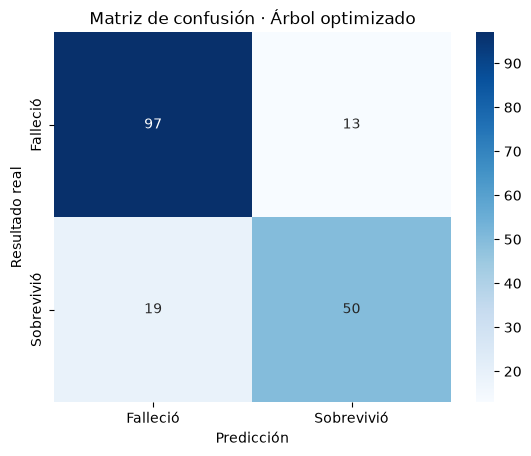

In [159]:
matriz = confusion_matrix(y_test, pred_test, labels=[0, 1])

sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Falleció", "Sobrevivió"],
    yticklabels=["Falleció", "Sobrevivió"]
)
plt.xlabel("Predicción")
plt.ylabel("Resultado real")
plt.title("Matriz de confusión · Árbol optimizado")
plt.show()

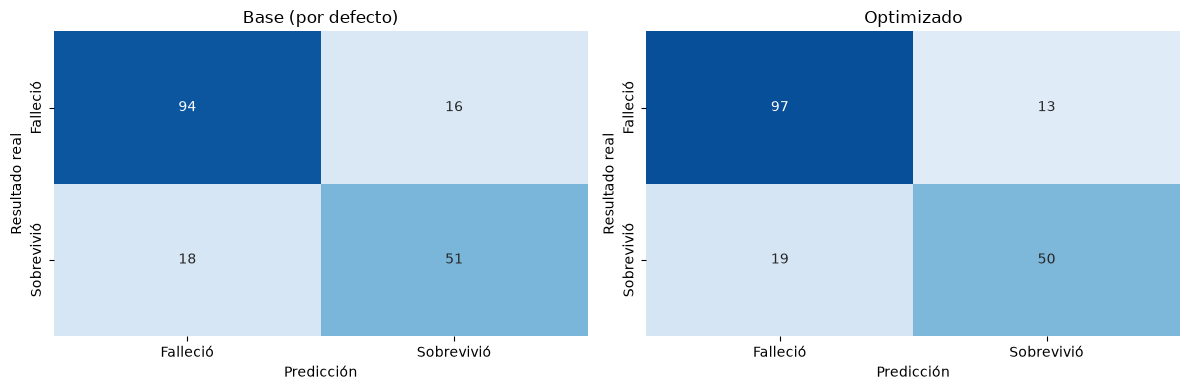

In [160]:
modelos = {
    "Base (por defecto)": modelo_base_arbol,
    "Optimizado": modelo_opt_arbol,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for (nombre, modelo), ax in zip(modelos.items(), axes):
    predicciones = modelo.predict(X_test)
    matriz_actual = confusion_matrix(y_test, predicciones, labels=[0, 1])

    sns.heatmap(
        matriz_actual, annot=True, fmt="d", cmap="Blues",
        vmin=0, vmax=y_test.value_counts().max(), cbar=False,
        xticklabels=["Falleció", "Sobrevivió"],
        yticklabels=["Falleció", "Sobrevivió"],
        ax=ax,
    )
    ax.set(title=nombre, xlabel="Predicción", ylabel="Resultado real")

plt.tight_layout()
plt.show()

KNN